# 02 · Band-power features and a subject-level baseline

**Goal:** turn each participant's EEG into a short list of numbers (**features**) and test whether they separate ADHD from Control. We always test on participants the model has never seen.

**How it fits the project:** before reproducing the segment-wise (leaky) split in notebook 03, we need a subject-wise reference result. This notebook asks: with simple, standard EEG features and one row per participant, how well can we really do?

We also test the **theta/beta ratio (TBR)**, the best-known proposed EEG marker of ADHD. Many earlier studies reported higher TBR in ADHD, but later studies did not consistently confirm it.

**Question:** Can we turn each participant's recording into one row of features?

**How:**
`band_features` (in `src/features.py`) does this for every participant:
1. **Band-pass 1–40 Hz**, the same clean-up as in notebook 00.
2. **Welch PSD** with `n_fft=512`, i.e. 4-second segments (512 ÷ 128). The spectrum of each segment is averaged, which gives a 0.25 Hz frequency resolution.
3. **Band power**: add up the PSD inside theta (4–8 Hz), alpha (8–13 Hz) and beta (13–30 Hz).
4. **Relative power**: band power ÷ total power (1–40 Hz) on the same channel, a number between 0 and 1. This removes overall loudness differences between participants, such as skull thickness or electrode contact. It is like giving a share of a budget instead of the amount in euros.
5. **TBR** = theta power ÷ beta power.

19 channels × (3 relative powers + 1 TBR) = 76 features. We also store each participant's recording length (`seconds`).

**What we found:** `(121, 76)`: one row per participant and 76 features, as expected.

In [ ]:
import sys; sys.path.append("..")
import pandas as pd
from src.load import list_subjects, load_subject
from src.features import band_features

df = pd.DataFrame(list_subjects())
df["seconds"] = [load_subject(p).shape[1] / 128 for p in df.path]
feats = pd.DataFrame([band_features(load_subject(p)) for p in df.path])
print(feats.shape)            # expect (121, 76)

**Question:** Do ADHD participants have a higher theta/beta ratio at Cz, as often reported?

**How:**
1. Take the TBR at Cz (top centre of the head) and summarise it per group.
2. **Mann-Whitney U test**: compares two groups without assuming a bell-shaped distribution. It ranks all values together and checks whether one group's ranks tend to be higher.
3. The **p-value** is the chance of seeing a difference at least this large if there were truly no group difference. A small p (e.g. < 0.05) suggests a real difference.
4. Box plot per group.

**What we found:** ADHD median **3.39** vs Control **3.72**. ADHD is slightly *lower*, the opposite of the classic claim. **p = 0.19**, so there is no significant difference. Both groups are widely spread (Control ranges from 0.55 to 11.17). In this dataset, TBR at Cz does not separate the groups. One caveat: TBR is often measured at rest, while these participants were doing a task (per the dataset description), which may change TBR.

         count  mean   std   min   25%   50%   75%    max
group                                                    
ADHD      61.0  3.61  1.69  1.21  2.16  3.39  4.77   8.62
Control   60.0  4.14  2.22  0.55  2.60  3.72  5.17  11.17
p = 0.1888


<Axes: title={'center': 'tbr_Cz'}, xlabel='group'>

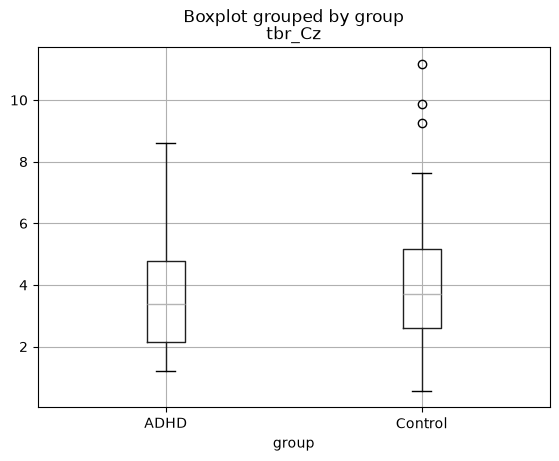

In [2]:
from scipy.stats import mannwhitneyu
df["tbr_Cz"] = feats["tbr_Cz"]
print(df.groupby("group").tbr_Cz.describe().round(2))
print("p =", mannwhitneyu(df.tbr_Cz[df.label == 1], df.tbr_Cz[df.label == 0]).pvalue.round(4))
df.boxplot(column="tbr_Cz", by="group")

**Question:** How well can a simple classifier predict ADHD from each feature set when tested on unseen participants?

**How:**
1. `RepeatedStratifiedKFold(n_splits=5, n_repeats=10)` runs 5-fold cross-validation 10 times, each time with a different shuffle. That gives 50 test scores, and their average is more stable than one 5-fold run. One row = one participant, so no participant is ever in both training and test data.
2. `make_pipeline(StandardScaler(), LogisticRegression())`: **StandardScaler** rescales each feature to mean 0 and std 1, so features on different scales are treated fairly. Inside a pipeline, the scaling is learned from the training part only. This prevents a small leak of test information.
3. Four feature sets are tried: recording-duration baseline, TBR at Cz only, all 76 EEG features, and EEG + duration.
4. Each prints the mean AUC ± std over the 50 test folds.

**What we found:** | features | AUC |
|---|---|
| recording-duration baseline | 0.65 ± 0.11 |
| TBR at Cz | 0.57 ± 0.11 |
| all 76 EEG | 0.54 ± 0.09 |
| EEG + duration | 0.63 ± 0.08 |

The best predictor is **not EEG at all**: it is recording length. All 76 EEG features together reach only 0.54, barely above coin-flip (0.5). Adding them to length makes it slightly *worse* (0.63 < 0.65), so they add noise rather than signal. With only 121 participants and 76 features, the model has many "knobs" and few examples, so it easily fits noise (**overfitting**).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
y = df.label

for name, X in {"recording-duration baseline": df[["seconds"]],
                "TBR at Cz":   df[["tbr_Cz"]],
                "all 76 EEG":  feats,
                "EEG + duration": feats.assign(seconds=df.seconds)}.items():
    s = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    print(f"{name:13s} AUC {s.mean():.2f} ± {s.std():.2f}")

## Key takeaways
- Each participant is summarised by 76 features: relative theta/alpha/beta power and TBR on 19 channels.
- TBR at Cz shows no group difference (p = 0.19), and ADHD is slightly lower, not higher.
- With subject-wise testing: recording-duration baseline 0.65 > TBR at Cz 0.57 > all EEG 0.54. EEG + duration gives 0.63.
- Simple band-power EEG features do not beat the non-brain baseline (recording length).
- This is the subject-wise reference point for the comparison in notebook 03.

## Open questions
- Would fewer features, a regularised model or a random forest do better at the subject level?
- Would removing artifacts (EMG at T8, EOG) change the results?
- Are absolute band powers more informative than relative ones?
- Does cropping all recordings to the same length change the EEG-only results?